# Quantum Kernels y Quantum Support Vector Classification (QSVC)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mateo-Giacometti/tp_computacion_cuantica/blob/main/qsvc/notebooks/qsvc.ipynb)

En este notebook se desarrolla la sección dedicada a *quantum kernels* y QSVC del trabajo práctico de Computación Cuántica sobre Quantum Machine Learning. Mediante simulaciones en [PennyLane](https://docs.pennylane.ai/) y [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), se implementa la evaluación de kernels cuánticos, se compara su desempeño frente a kernels clásicos en distintos datasets y se analizan sus principales limitaciones prácticas.

1. Del aprendizaje supervisado clásico a los quantum kernels
2. Clasificación con quantum kernels y rol del entrelazamiento
3. Inductive bias y adaptación del kernel
4. Limitaciones prácticas y escalabilidad

*Nota: las funciones auxiliares de datasets y gráficos se encuentran separadas en `qsvc/src/`.*

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/tp_computacion_cuantica")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Mateo-Giacometti/tp_computacion_cuantica.git", str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=False)
    if importlib.util.find_spec("pennylane") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pennylane>=0.45"], check=True)
    BASE_DIR = REPO_DIR / "qsvc"
else:
    BASE_DIR = Path("..").resolve()

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
from sklearn.svm import SVC
from src import datasets as ds, plots as pl

FIGURES_DIR = pl.init_environment(BASE_DIR / "figuras")

## 1. Del aprendizaje supervisado clásico a los quantum kernels

En un problema de aprendizaje supervisado de clasificación disponemos de un dataset de train formado por pares $(\mathbf{x}_i, y_i)$, donde cada $\mathbf{x}_i$ es un vector de features y $y_i \in \{-1, +1\}$ indica su clase. El objetivo es aprender una regla de decisión que prediga correctamente la clase de observaciones nuevas de test.

Una *Support Vector Machine* (SVM) clásica ([Cortes y Vapnik, 1995](https://doi.org/10.1007/BF00994018)) resuelve esta tarea buscando el hiperplano $\boldsymbol{\theta}^T \mathbf{x} + b = 0$ que separa ambas clases con el mayor margen posible. Esta estrategia funciona cuando los datos son linealmente separables, pero falla cuando las clases están dispuestas de modo que ninguna recta o plano puede dividirlas.

Consideremos el caso simple de un dataset unidimensional con un único feature $x \in [-\pi, \pi]$, donde los puntos cercanos al origen pertenecen a una clase y ambos extremos pertenecen a la clase opuesta. Como se observa en la figura siguiente, ningún corte único sobre la recta permite separar ambas regiones.

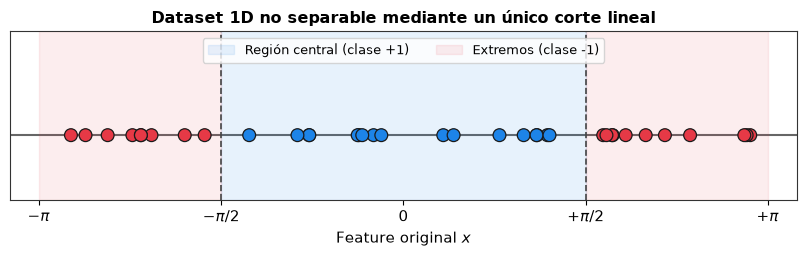

In [2]:
X1_train, X1_test, y1_train, y1_test = ds.make_1d_blocks()
pl.plot_1d_dataset(X1_train, y1_train)

Para resolver problemas no linealmente separables se introduce una transformación $\phi(\mathbf{x})$ (*feature map*) que proyecta cada dato hacia un espacio de mayor dimensión donde sí exista un hiperplano separador $\boldsymbol{\theta}^T \phi(\mathbf{x}) + b = 0$. El problema original de la SVM consiste en encontrar los pesos $\boldsymbol{\theta}$ y el *bias* $b$ de máximo margen en ese espacio transformado.

$$\min_{\boldsymbol{\theta}, b} \; \frac{1}{2}\|\boldsymbol{\theta}\|^2 \qquad \text{sujeto a} \quad y_i\big(\boldsymbol{\theta}^T \phi(\mathbf{x}_i) + b\big) \ge 1$$

Cuando $\phi(\mathbf{x})$ vive en un espacio de dimensión muy grande, calcular sus coordenadas y optimizar $\boldsymbol{\theta}$ de forma directa se vuelve inviable. Sin embargo, este problema resulta matemáticamente equivalente a una formulación dual en función de pesos escalares $\alpha_i$, donde los *feature maps* únicamente intervienen multiplicados entre sí mediante productos internos. A esa función de similitud entre pares de datos se la denomina **kernel**, $k(\mathbf{x}_i, \mathbf{x}_j) = \phi(\mathbf{x}_i)^T \phi(\mathbf{x}_j)$, y este recurso se conoce como *kernel trick* ([Cortes y Vapnik, 1995](https://doi.org/10.1007/BF00994018)).

$$\max_{\boldsymbol{\alpha}} \; \sum_{i=1}^{M} \alpha_i - \frac{1}{2} \sum_{i,j=1}^{M} \alpha_i \alpha_j y_i y_j \, k(\mathbf{x}_i, \mathbf{x}_j), \qquad \hat{y}(\mathbf{x}) = \operatorname{sign}\!\left( \sum_{i \in SV} \alpha_i y_i \, k(\mathbf{x}_i, \mathbf{x}) + b \right)$$

En una computadora clásica solo podemos utilizar kernels cuya similitud resulte eficiente de calcular, como el lineal, el polinomial o el RBF. La motivación de los *quantum kernels* ([Havlíček et al., 2019](https://arxiv.org/abs/1804.11326), [Schuld y Killoran, 2019](https://arxiv.org/abs/1803.07128) y [Schuld y Petruccione, 2021](https://doi.org/10.1007/978-3-030-83098-4)) proviene de una cuestión de complejidad computacional. Un registro de $n$ qubits opera de forma nativa en un espacio de Hilbert de dimensión $2^n$. Al codificar un dato clásico en un estado cuántico $|\phi(\mathbf{x})\rangle = U(\mathbf{x})|0\rangle^{\otimes n}$, el circuito cuántico actúa como *feature map* y la similitud entre dos puntos queda definida por el solapamiento entre sus estados, $k(\mathbf{x}, \mathbf{x}') = |\langle \phi(\mathbf{x}') \mid \phi(\mathbf{x}) \rangle|^2$. Existen familias de circuitos con superposición, entrelazamiento e interferencia cuyas similitudes se conjeturan intratables de calcular clásicamente para muchos qubits, pero que una QPU puede estimar directamente mediante mediciones con circuitos cortos aptos para hardware NISQ. En el plano teórico, [Liu, Arunachalam y Temme (2021)](https://arxiv.org/abs/2010.02174) demostraron incluso una ventaja exponencial rigurosa de QSVC para un problema basado en el logaritmo discreto, aunque requiere hardware tolerante a fallos.

Para ilustrar este mecanismo en el caso mínimo, volvamos al dataset 1D anterior y codifiquemos cada punto en un único qubit mediante una rotación $R_Y(x)|0\rangle$. Sobre la esfera de Bloch, los puntos del intervalo central quedan agrupados cerca de $|0\rangle$, mientras que ambos extremos convergen juntos hacia $|1\rangle$. En ese espacio, el plano horizontal $z = 0$ separa ambas clases por completo y el kernel cuántico adopta una expresión cerrada.

$$k(x, x') = \big|\langle \phi(x') \mid \phi(x) \rangle\big|^2 = \cos^2\!\left(\frac{x - x'}{2}\right)$$

Error máximo frente a cos^2((x-x')/2) = 4.44e-16
SVM lineal en 1D = 55.0% | QSVC de 1 qubit = 100.0%


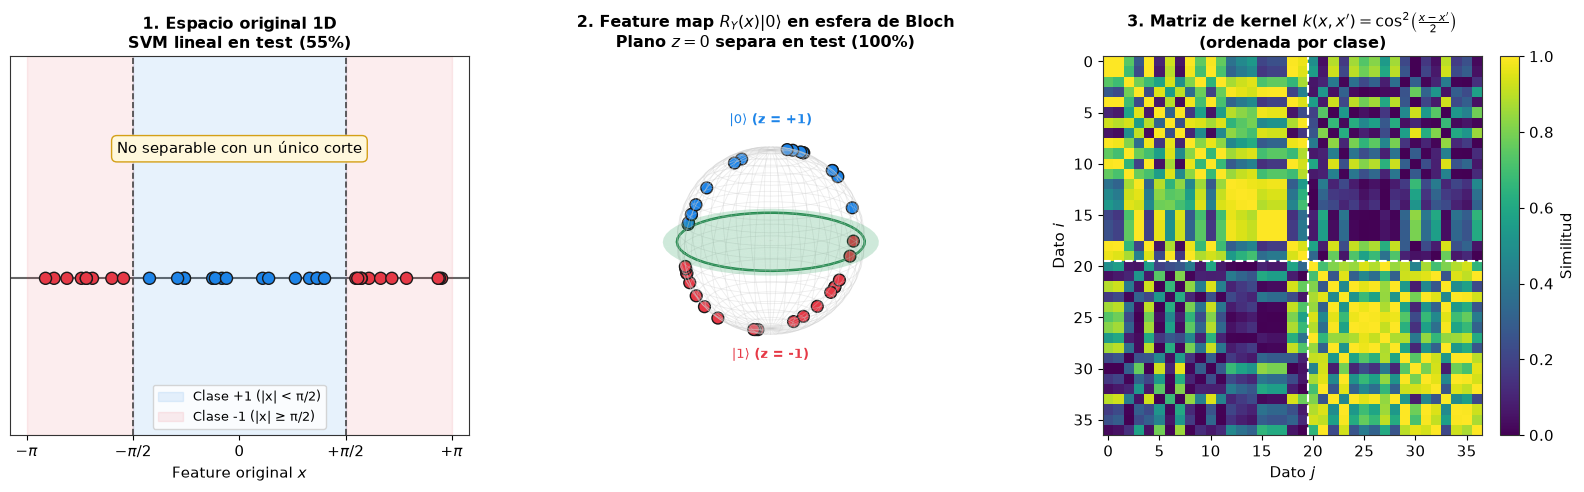

In [3]:
# default.qubit simula de forma exacta el vector de estado de 1 qubit
dev_1q = qml.device("default.qubit", wires=1)

# @qml.qnode convierte la función Python en un circuito cuántico ejecutable
@qml.qnode(dev_1q)
def kernel_1q(x1, x2):
    qml.RY(x1, wires=0)               # U(x1)|0> = cos(x1/2)|0> + sin(x1/2)|1>
    qml.adjoint(qml.RY)(x2, wires=0)  # aplica la operación inversa U†(x2) = RY(-x2)
    return qml.probs(wires=0)         # devuelve [P(|0>), P(|1>)], con P(|0>) = k(x1, x2)

def compute_kernel_1q(A, B):
    return np.array([[float(kernel_1q(a[0], b[0])[0]) for b in B] for a in A])

K1_train = compute_kernel_1q(X1_train, X1_train)
K1_test = compute_kernel_1q(X1_test, X1_train)

acc_lin_1d = SVC(kernel="linear").fit(X1_train, y1_train).score(X1_test, y1_test)
acc_q_1d = SVC(kernel="precomputed").fit(K1_train, y1_train).score(K1_test, y1_test)

max_error = np.max(np.abs(K1_train - np.cos((X1_train - X1_train.T) / 2.0) ** 2))
print(f"Error máximo frente a cos^2((x-x')/2) = {max_error:.2e}")
print(f"SVM lineal en 1D = {acc_lin_1d:.1%} | QSVC de 1 qubit = {acc_q_1d:.1%}")

pl.plot_bloch_mapping(X1_train, y1_train, K1_train, acc_lin_1d, acc_q_1d, FIGURES_DIR / "01_intuicion_esfera_bloch.png")

## 2. Clasificación con quantum kernels y rol del entrelazamiento

Al extender la idea a $n$ qubits, el QSVC divide el algoritmo entre la unidad cuántica y la computadora clásica ([Havlíček et al., 2019](https://arxiv.org/abs/1804.11326)). La QPU no entrena parámetros del circuito ni reconstruye el estado cuántico completo, sino que estima cada entrada de la matriz de kernel $K_{ij}$ mediante el protocolo *compute uncompute*. Para un par de datos $(\mathbf{x}_i, \mathbf{x}_j)$, se aplica primero el circuito de codificación $U(\mathbf{x}_i)$, luego su operación inversa $U^\dagger(\mathbf{x}_j)$, y finalmente se mide la probabilidad de retornar al estado inicial $|00\dots 0\rangle$.

$$K_{ij} = k(\mathbf{x}_i, \mathbf{x}_j) = \big|\langle 0^{\otimes n} \mid U^\dagger(\mathbf{x}_j)\, U(\mathbf{x}_i) \mid 0^{\otimes n} \rangle\big|^2$$

Cuando dos observaciones son similares, $U^\dagger(\mathbf{x}_j)$ deshace casi por completo las transformaciones de $U(\mathbf{x}_i)$ y la interferencia constructiva concentra la probabilidad en $|00\dots 0\rangle$. Una vez construida la matriz $K$, la computadora clásica resuelve el problema dual convexo de la SVM con óptimo global garantizado y determina los *support vectors* ($\alpha_i > 0$). Desde el punto de vista teórico, [Schuld (2021)](https://arxiv.org/abs/2101.11020) demostró además que cualquier modelo cuántico supervisado con codificación fija admite una formulación equivalente como método de kernel.

### Elección del feature map

En un QSVC toda la expresividad del clasificador reside en la definición del operador unitario $U(\mathbf{x})$ que codifica un vector de features $\mathbf{x} = (x_1, \dots, x_n)$ en $n$ qubits. Para estudiar su impacto en un problema bidimensional ($n = 2$), comparamos dos codificaciones estándar.

El *Angle Embedding* aplica una rotación independiente a cada qubit según el valor de su feature, $U_{\text{angle}}(\mathbf{x}) = R_Y(x_1) \otimes R_Y(x_2)$. Al no incluir compuertas de dos qubits, genera un estado separable (estado producto) cuyo kernel se factoriza como un producto de cosenos, evaluable de forma clásica en tiempo lineal.

El *IQP* o *ZZ Feature Map* ([Havlíček et al., 2019](https://arxiv.org/abs/1804.11326)) incorpora entrelazamiento para capturar correlaciones no lineales entre pares de features. Cada capa aplica compuertas Hadamard $H^{\otimes 2}$ para crear superposición, seguidas de rotaciones de fase individuales $R_Z(x_1)$ y $R_Z(x_2)$ y de una interacción entrelazante de dos qubits $\exp(-i\frac{x_1 x_2}{2} Z_1 Z_2)$ que en el circuito se descompone como `CNOT`, `RZ(x_1 x_2)` y `CNOT`. Repetir este bloque $r$ veces ($r = 2$ en el ejemplo) incrementa la complejidad de la interferencia cuántica.

$$U_{\text{IQP}}(\mathbf{x}) = \Big(\, \exp\!\big(-i\tfrac{x_1 x_2}{2} Z_1 Z_2\big)\,\big(R_Z(x_1) \otimes R_Z(x_2)\big)\, H^{\otimes 2} \,\Big)^r$$

En el código siguiente implementamos ambas codificaciones en PennyLane, verificamos numéricamente que el protocolo *compute uncompute* coincide con el solapamiento directo $|\langle \phi(\mathbf{x}_b) \mid \phi(\mathbf{x}_a) \rangle|^2$, y visualizamos el circuito resultante para una capa de $U_{\text{IQP}}(\mathbf{x})$ seguida de su inverso $U_{\text{IQP}}^\dagger(\mathbf{x}')$ después de la barrera vertical.

Probabilidad P(|00>) en circuito compute uncompute = 0.704071486230
Fidelidad directa |<phi(x_b)|phi(x_a)>|^2          = 0.704071486230


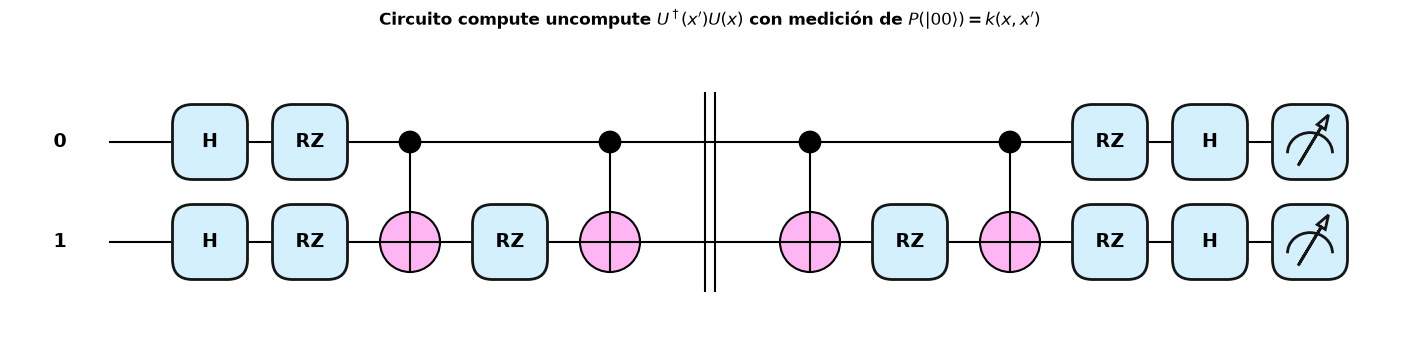

In [4]:
dev_2q = qml.device("default.qubit", wires=2)

@qml.qnode(dev_2q)
def iqp_fidelity_circuit(x1, x2):
    # IQPEmbedding aplica Hadamard, fases RZ(x_i) y entrelazamiento ZZ(x_i * x_j)
    qml.IQPEmbedding(x1, wires=[0, 1], n_repeats=2)
    qml.adjoint(qml.IQPEmbedding)(x2, wires=[0, 1], n_repeats=2)
    return qml.probs(wires=[0, 1])

@qml.qnode(dev_2q)
def iqp_state(x):
    qml.IQPEmbedding(x, wires=[0, 1], n_repeats=2)
    return qml.state()  # devuelve el vector de estado |phi(x)> completo en simulación

@qml.qnode(dev_2q)
def angle_state(x):
    # AngleEmbedding codifica cada feature en un qubit independiente (estado separable)
    qml.AngleEmbedding(x, wires=[0, 1], rotation="Y")
    return qml.state()

def compute_state_kernel(state_fn, A, B):
    states_a = np.array([state_fn(a) for a in A])
    states_b = np.array([state_fn(b) for b in B])
    return np.abs(states_a.conj() @ states_b.T) ** 2

x_a, x_b = np.array([0.8, 2.1]), np.array([1.2, 1.7])
print(f"Probabilidad P(|00>) en circuito compute uncompute = {float(iqp_fidelity_circuit(x_a, x_b)[0]):.12f}")
print(f"Fidelidad directa |<phi(x_b)|phi(x_a)>|^2          = {float(np.abs(np.vdot(iqp_state(x_b), iqp_state(x_a)))**2):.12f}")

pl.plot_compute_uncompute_circuit(x_a, x_b, FIGURES_DIR / "02_circuito_compute_uncompute.png")

Con ambas codificaciones definidas, evaluamos su desempeño en el dataset `make_moons` comparando cuatro modelos. Se contrasta una SVM lineal clásica, un QSVC con *Angle Embedding* sin entrelazamiento, un QSVC con *IQP Embedding* entrelazado y una SVM clásica con kernel RBF.

SVM lineal                   | Test = 79.2% | Support vectors = 35
QSVC Angle (separable)       | Test = 79.2% | Support vectors = 40
QSVC ZZ / IQP (entrelazado)  | Test = 81.2% | Support vectors = 65
SVM RBF clásica              | Test = 91.7% | Support vectors = 36


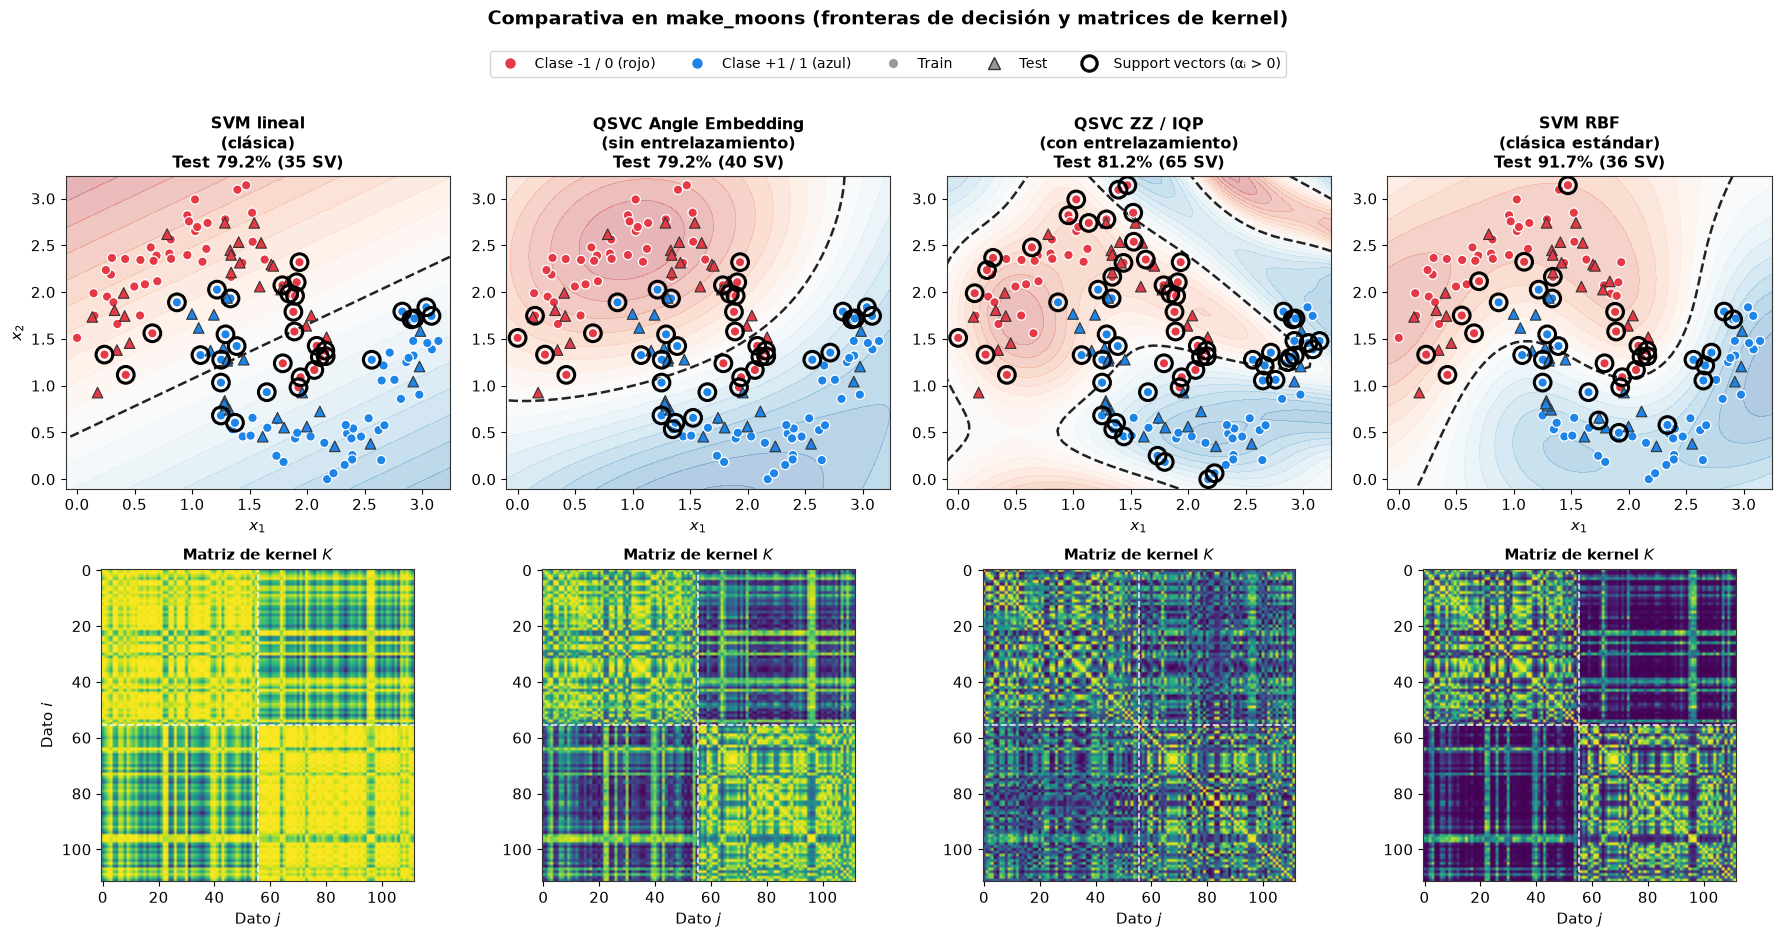

In [5]:
Xm_train, Xm_test, ym_train, ym_test = ds.load_moons_dataset()

K_angle_train = compute_state_kernel(angle_state, Xm_train, Xm_train)
K_angle_test = compute_state_kernel(angle_state, Xm_test, Xm_train)
K_iqp_train = compute_state_kernel(iqp_state, Xm_train, Xm_train)
K_iqp_test = compute_state_kernel(iqp_state, Xm_test, Xm_train)

clf_linear = SVC(kernel="linear").fit(Xm_train, ym_train)
clf_angle = SVC(kernel="precomputed").fit(K_angle_train, ym_train)
clf_iqp = SVC(kernel="precomputed").fit(K_iqp_train, ym_train)
clf_rbf = SVC(kernel="rbf").fit(Xm_train, ym_train)

accs = [
    clf_linear.score(Xm_test, ym_test),
    clf_angle.score(K_angle_test, ym_test),
    clf_iqp.score(K_iqp_test, ym_test),
    clf_rbf.score(Xm_test, ym_test),
]
labels = ["SVM lineal", "QSVC Angle (separable)", "QSVC ZZ / IQP (entrelazado)", "SVM RBF clásica"]
for name, acc, clf in zip(labels, accs, [clf_linear, clf_angle, clf_iqp, clf_rbf]):
    print(f"{name:28s} | Test = {acc:5.1%} | Support vectors = {len(clf.support_)}")

pl.plot_moons_comparison(
    Xm_train, Xm_test, ym_train, ym_test,
    {"clfs": [clf_linear, clf_angle, clf_iqp, clf_rbf], "K_angle_train": K_angle_train, "K_iqp_train": K_iqp_train, "accs": accs},
    compute_state_kernel, angle_state, iqp_state,
    FIGURES_DIR / "03_comparativa_moons_4_modelos.png",
)

## 3. Inductive bias y adaptación del kernel

### 3.1 Benchmark sintético de Havlíček et al. (2019)

En datasets clásicos de baja dimensión como `make_moons`, el kernel RBF suele superar al QSVC, en concordancia con los benchmarks sistemáticos de [Bowles, Ahmed y Schuld (2024)](https://arxiv.org/abs/2403.07059). Este comportamiento responde al *inductive bias*, es decir, a qué tan bien coincide la noción de similitud del kernel con la estructura real de los datos.

Para observar el caso opuesto, evaluamos el dataset sintético introducido por [Havlíček et al. (2019)](https://arxiv.org/abs/1804.11326). Cada entrada $\mathbf{x} = (x_1, x_2) \in [0, 2\pi]^2$ es un vector clásico de dos coordenadas reales, pero las etiquetas se fabrican a partir de un hiperplano en el espacio de Hilbert del *ZZ Feature Map*. Concretamente, se elige una transformación unitaria fija $V$ (desconocida para el clasificador) que rota el observable de medición $Z \otimes Z$ y fija así la orientación del plano separador en el espacio de estados. Para cada punto codificado $|\Phi(\mathbf{x})\rangle$, se evalúa el valor medio $s(\mathbf{x}) = \langle \Phi(\mathbf{x}) \mid V^\dagger (Z \otimes Z) V \mid \Phi(\mathbf{x}) \rangle$ y se asigna clase $+1$ si $s(\mathbf{x}) \ge \Delta$ o clase $-1$ si $s(\mathbf{x}) \le -\Delta$. Por construcción, las clases resultan linealmente separables en el espacio cuántico del circuito, aunque proyectadas sobre el plano clásico $(x_1, x_2)$ forman múltiples regiones desconectadas generadas por interferencia de fases.

Dataset sintético (Havlíček et al., 2019) | QSVC = 100.0% | SVM RBF clásica = 80.0%


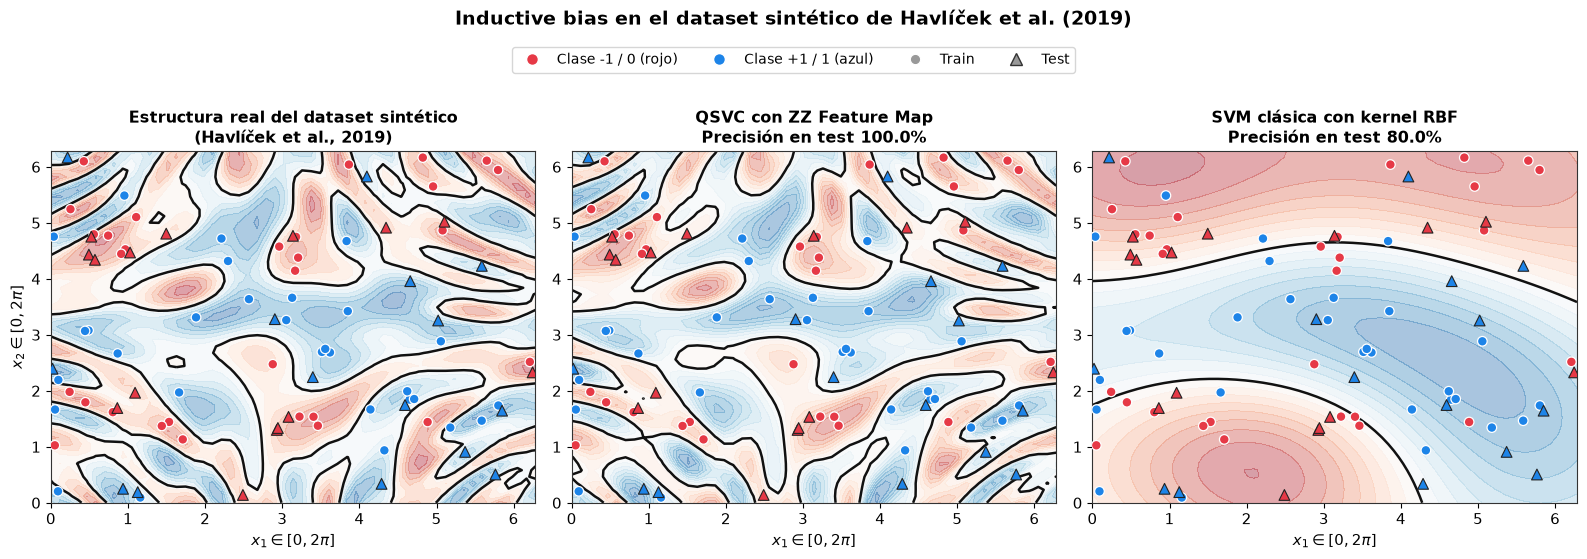

In [6]:
Xhv_train, Xhv_test, yhv_train, yhv_test, hv_grid = ds.make_havlicek_dataset()

@qml.qnode(dev_2q)
def zz_state(x):
    ds.zz_feature_map(x)  # 2 repeticiones de H, RZ(2x_i) y acoplamiento ZZ
    return qml.state()

Khv_train = compute_state_kernel(zz_state, Xhv_train, Xhv_train)
Khv_test = compute_state_kernel(zz_state, Xhv_test, Xhv_train)

qsvc_hv = SVC(kernel="precomputed", C=10.0).fit(Khv_train, yhv_train)
rbf_hv = SVC(kernel="rbf").fit(Xhv_train, yhv_train)

acc_q_hv = qsvc_hv.score(Khv_test, yhv_test)
acc_rbf_hv = rbf_hv.score(Xhv_test, yhv_test)
print(f"Dataset sintético (Havlíček et al., 2019) | QSVC = {acc_q_hv:.1%} | SVM RBF clásica = {acc_rbf_hv:.1%}")

pl.plot_havlicek_comparison(
    Xhv_train, Xhv_test, yhv_train, yhv_test, hv_grid, qsvc_hv, rbf_hv,
    acc_q_hv, acc_rbf_hv, compute_state_kernel, zz_state,
    FIGURES_DIR / "04_sesgo_inductivo_havlicek.png",
)

### 3.2 Extensión con kernel entrenable (Quantum Kernel Alignment)

Cuando un *feature map* fijo no captura la estructura del dataset, una extensión posible consiste en introducir parámetros entrenables $\boldsymbol{\theta}$ dentro del circuito de codificación $U(\mathbf{x}, \boldsymbol{\theta})$ y ajustarlos mediante descenso por el gradiente antes de entrenar la SVM. A diferencia de una QNN, donde el circuito predice directamente la etiqueta de cada punto, aquí el clasificador final sigue siendo una SVM clásica sobre la matriz de kernel $K_{ij}(\boldsymbol{\theta}) = |\langle 0^{\otimes n} \mid U^\dagger(\mathbf{x}_j, \boldsymbol{\theta}) U(\mathbf{x}_i, \boldsymbol{\theta}) \mid 0^{\otimes n} \rangle|^2$. El rol del descenso por el gradiente (con el optimizador Adam) es únicamente moldear el *feature map* maximizando el *Kernel Target Alignment* ([Cristianini et al., 2001](https://proceedings.neurips.cc/paper_files/paper/2001/hash/1f71e393b3809197ed66df836fe833e5-Abstract.html) y [Hubregtsen et al., 2022](https://arxiv.org/abs/2105.02276)), que mide la alineación entre $K(\boldsymbol{\theta})$ y la matriz ideal de etiquetas $y_i y_j$.

$$\operatorname{KTA}(\boldsymbol{\theta}) = \frac{\sum_{i,j} K_{ij}(\boldsymbol{\theta})\, y_i y_j}{M \sqrt{\sum_{i,j} K_{ij}(\boldsymbol{\theta})^2}}$$

En el experimento sobre el dataset `DoubleCake`, el circuito $U(\mathbf{x}, \boldsymbol{\theta})$ utiliza 4 qubits y 4 capas repetidas. En cada capa, cada qubit aplica una rotación $R_X$ que codifica uno de los dos features ($x_1$ en los qubits pares y $x_2$ en los impares, escalado y desplazado por parámetros de $\boldsymbol{\theta}$), una rotación $R_Y$ que incorpora el término cruzado $x_1 x_2$, y un anillo de compuertas controladas `CRZ` que entrelaza cada qubit con su vecino.

Paso  0 | KTA = 0.002 | Precisión en test = 66.7%


Paso 10 | KTA = 0.193 | Precisión en test = 95.8%


Paso 30 | KTA = 0.377 | Precisión en test = 95.8%


Paso 55 | KTA = 0.457 | Precisión en test = 95.8%


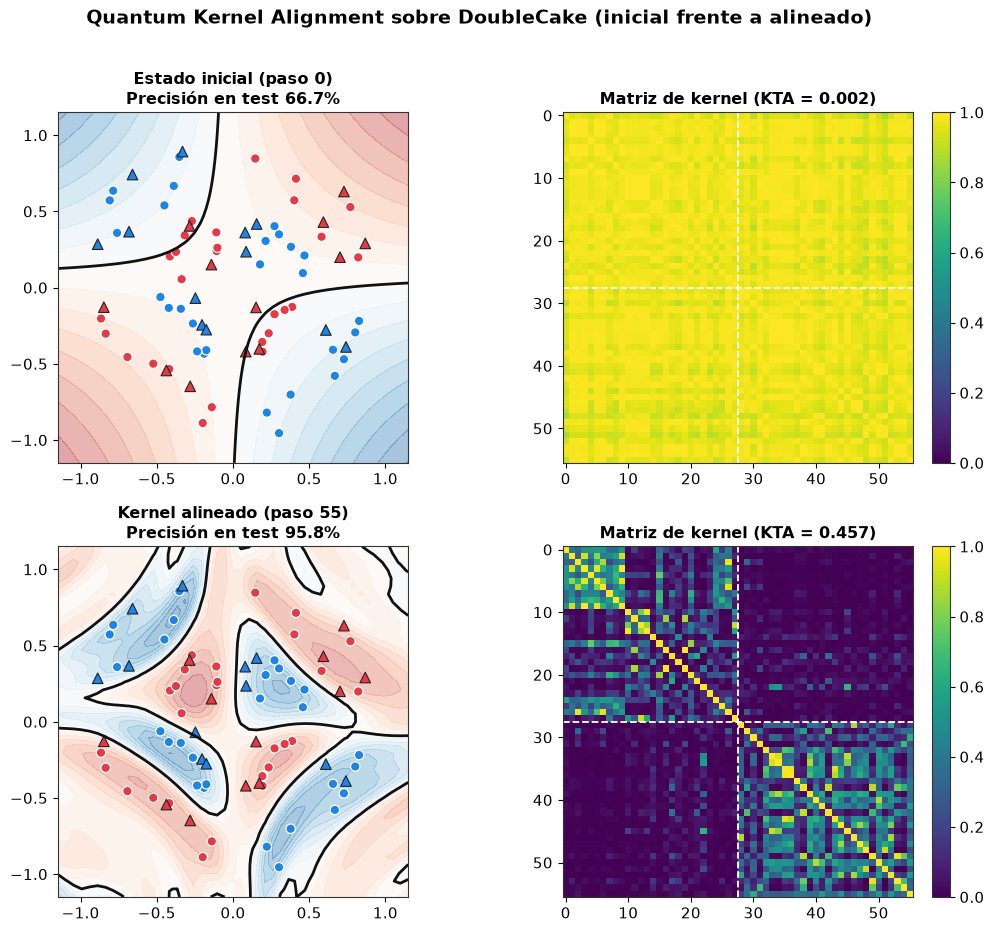

In [7]:
Xdc_train, Xdc_test, ydc_train, ydc_test = ds.make_double_cake_dataset()
N_QUBITS, N_LAYERS = 4, 4
dev_qek = qml.device("default.qubit", wires=N_QUBITS)

# interface="autograd" habilita la diferenciación automática respecto de params
@qml.qnode(dev_qek, interface="autograd")
def qek_states(x1, x2, params):
    for layer in range(N_LAYERS):
        for q in range(N_QUBITS):
            feature = x1 if q % 2 == 0 else x2
            qml.RX(params[layer, q, 0] * feature + params[layer, q, 1], wires=q)
            qml.RY(params[layer, q, 2] * (x1 * x2) + params[layer, q, 3], wires=q)
        for q in range(N_QUBITS):
            qml.CRZ(params[layer, q, 4], wires=[q, (q + 1) % N_QUBITS])  # rotación Z controlada entre vecinos
    return qml.state()

def qek_kernel(A, B, params):
    states_a = qek_states(A[:, 0], A[:, 1], params)
    states_b = qek_states(B[:, 0], B[:, 1], params)
    overlap = pnp.dot(pnp.conj(states_a), pnp.transpose(states_b))
    return pnp.real(overlap * pnp.conj(overlap))

def kta_score(params, X, y):
    K = qek_kernel(X, X, params)
    return pnp.sum(K * pnp.outer(y, y)) / (len(y) * pnp.sqrt(pnp.sum(K * K) + 1e-12))

pnp.random.seed(42)
params = pnp.random.uniform(-0.25, 0.25, size=(N_LAYERS, N_QUBITS, 5), requires_grad=True)
opt = qml.AdamOptimizer(stepsize=0.12)

N_STEPS = 55
saved_steps = [0, 2, 4, 6, 8, 10, 14, 18, 24, 32, 42, 55]
Xdc_tr_p, Xdc_te_p = pnp.array(Xdc_train, requires_grad=False), pnp.array(Xdc_test, requires_grad=False)
ydc_tr_p = pnp.array(ydc_train, requires_grad=False)

hist_kta, hist_acc, snapshots = [], [], {}
for step in range(N_STEPS + 1):
    kta_val = float(kta_score(params, Xdc_tr_p, ydc_tr_p))
    K_tr_np = np.array(qek_kernel(Xdc_tr_p, Xdc_tr_p, params))
    K_te_np = np.array(qek_kernel(Xdc_te_p, Xdc_tr_p, params))
    clf = SVC(kernel="precomputed", C=5.0).fit(K_tr_np, ydc_train)
    acc_val = clf.score(K_te_np, ydc_test)

    hist_kta.append(kta_val)
    hist_acc.append(acc_val)
    if step in saved_steps:
        snapshots[step] = (params.copy(), K_tr_np.copy(), clf, kta_val, acc_val)
    if step in (0, 10, 30, N_STEPS):
        print(f"Paso {step:2d} | KTA = {kta_val:.3f} | Precisión en test = {acc_val:.1%}")
    if step < N_STEPS:
        params = opt.step(lambda p: -kta_score(p, Xdc_tr_p, ydc_tr_p), params)

pl.generate_kta_gif(Xdc_train, Xdc_test, ydc_train, ydc_test, snapshots, hist_kta, hist_acc, saved_steps, N_STEPS, qek_kernel, FIGURES_DIR)

## 4. Limitaciones prácticas y escalabilidad

### 4.1 Concentración exponencial del kernel

Al aumentar el número de qubits $n$ con *feature maps* muy expresivos y entrelazantes, dos estados codificados distintos en un espacio de dimensión $2^n$ tienden a volverse casi ortogonales entre sí. [Thanasilp et al. (2024)](https://arxiv.org/abs/2208.11060) demostraron que, bajo estas condiciones, la varianza de los elementos fuera de la diagonal de la matriz de kernel decae exponencialmente con $n$.

$$\operatorname{Var}_{\mathbf{x} \neq \mathbf{x}'}\!\big[ k(\mathbf{x}, \mathbf{x}') \big] \in \mathcal{O}(b^{-n}), \qquad b > 1$$

Este fenómeno impacta directamente en dos etapas del QSVC. En la construcción de la matriz de kernel en la QPU, todos los valores fuera de la diagonal caen hacia cero mientras la diagonal permanece igual a uno, por lo que ante cualquier ruido de medición la matriz estimada colapsa hacia la matriz identidad ($K \approx I$). En consecuencia, en la etapa de predicción sobre datos nuevos de test, la similitud $k(\mathbf{x}_i, \mathbf{x})$ con cada *support vector* se vuelve prácticamente nula, la suma $\sum_{i \in SV} \alpha_i y_i k(\mathbf{x}_i, \mathbf{x})$ desaparece y el clasificador devuelve siempre la misma clase constante $\operatorname{sign}(b)$, perdiendo toda capacidad de generalización. A continuación medimos este efecto entre 2 y 10 qubits comparando un *IQP Embedding* de 3 capas frente a un *Angle Embedding* reescalado por $1/\sqrt{n}$.

n =  2 | IQP media = 0.3651, Var = 5.26e-02 | Angle reescalado Var = 8.60e-02
n =  4 | IQP media = 0.0782, Var = 5.23e-03 | Angle reescalado Var = 4.75e-02


n =  6 | IQP media = 0.0213, Var = 4.57e-04 | Angle reescalado Var = 2.81e-02


n =  8 | IQP media = 0.0039, Var = 1.23e-05 | Angle reescalado Var = 2.34e-02


n = 10 | IQP media = 0.0011, Var = 1.35e-06 | Angle reescalado Var = 2.01e-02


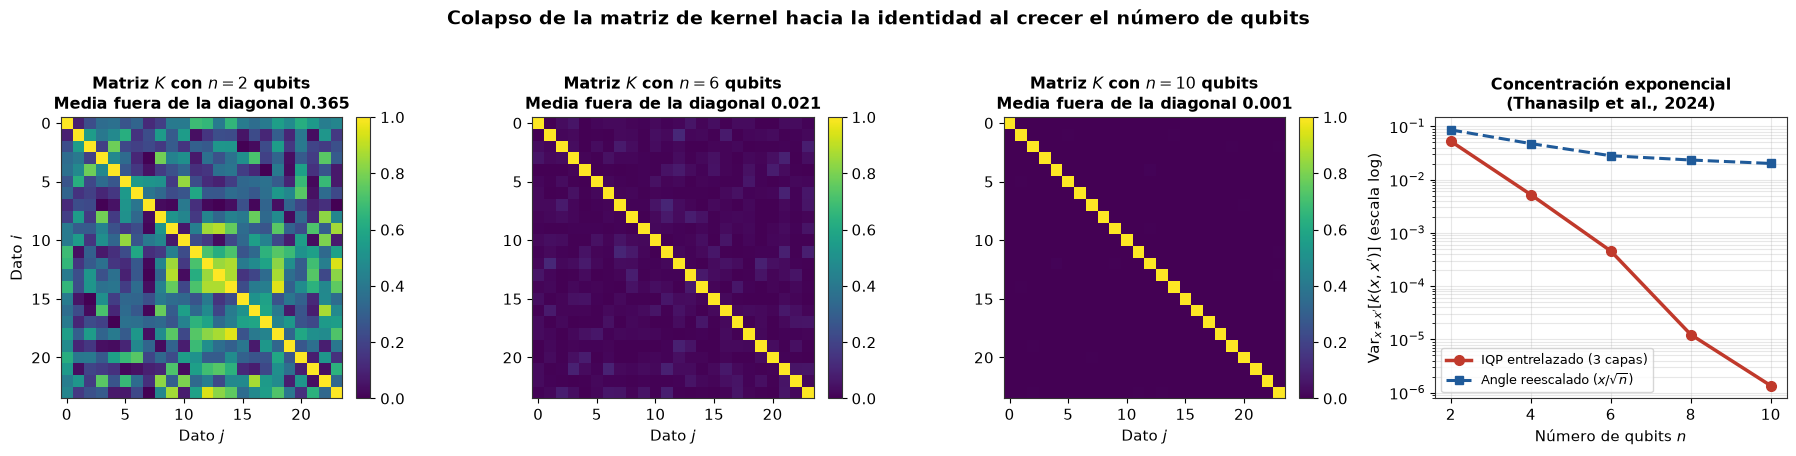

In [8]:
rng = np.random.default_rng(7)
qubit_counts = [2, 4, 6, 8, 10]
n_samples = 24
off_diag = ~np.eye(n_samples, dtype=bool)

var_iqp, mean_iqp, var_angle_scaled, sample_matrices = [], [], [], {}
for n_q in qubit_counts:
    X_rand = rng.uniform(0, 2 * np.pi, size=(n_samples, n_q))
    dev_n = qml.device("default.qubit", wires=n_q)

    @qml.qnode(dev_n)
    def iqp_state_n(x):
        qml.IQPEmbedding(x, wires=range(n_q), n_repeats=3)
        return qml.state()

    @qml.qnode(dev_n)
    def scaled_angle_state_n(x):
        qml.AngleEmbedding(x / np.sqrt(n_q), wires=range(n_q), rotation="Y")
        return qml.state()

    K_iqp = compute_state_kernel(iqp_state_n, X_rand, X_rand)
    K_ang = compute_state_kernel(scaled_angle_state_n, X_rand, X_rand)

    mean_iqp.append(float(np.mean(K_iqp[off_diag])))
    var_iqp.append(float(np.var(K_iqp[off_diag])))
    var_angle_scaled.append(float(np.var(K_ang[off_diag])))
    if n_q in (2, 6, 10):
        sample_matrices[n_q] = K_iqp

    print(f"n = {n_q:2d} | IQP media = {mean_iqp[-1]:.4f}, Var = {var_iqp[-1]:.2e} | Angle reescalado Var = {var_angle_scaled[-1]:.2e}")

pl.plot_exponential_concentration(qubit_counts, sample_matrices, mean_iqp, var_iqp, var_angle_scaled, FIGURES_DIR / "06_concentracion_exponencial.png")

### 4.2 Mediciones finitas y costo cuadrático

En hardware cuántico real no se accede directamente a las probabilidades exactas, sino que cada entrada $K_{ij}$ se estima repitiendo el circuito $S$ veces (*shots*) y calculando la frecuencia de aparición del estado $|00\dots 0\rangle$. Por muestreo binomial, esta estimación introduce un error estadístico del orden de $1/\sqrt{S}$ ([Havlíček et al., 2019](https://arxiv.org/abs/1804.11326)). Si además el kernel presenta concentración exponencial, distinguir las similitudes reales por encima del ruido exige una cantidad exponencial de *shots* ([Thanasilp et al., 2024](https://arxiv.org/abs/2208.11060)). A esto se suma el costo de construir la matriz de Gram de train, que demanda evaluar $\frac{M(M-1)}{2}$ pares distintos en la QPU y escala de manera cuadrática con el tamaño $M$ del dataset ([Schuld, 2021](https://arxiv.org/abs/2101.11020)).

Par (0, 1) | Exacto = 0.0622 | Estimado con 1000 shots = 0.0530


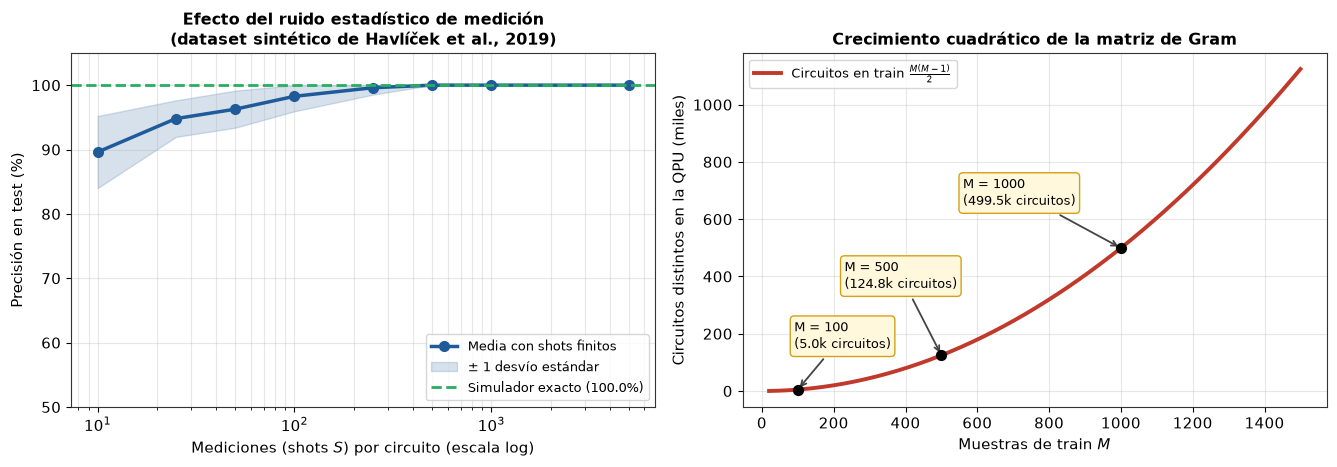

In [9]:
shots_list = [10, 25, 50, 100, 250, 500, 1000, 5000]
shot_means, shot_stds = ds.simulate_finite_shots(Khv_train, Khv_test, yhv_train, yhv_test, shots_list)

dev_shots = qml.device("default.qubit", wires=2)

# @qml.set_shots restringe la evaluación a S mediciones estadísticas reales
@qml.set_shots(1000)
@qml.qnode(dev_shots)
def finite_shot_kernel(x1, x2):
    ds.zz_feature_map(x1)
    qml.adjoint(ds.zz_feature_map)(x2)
    return qml.probs(wires=[0, 1])

k_est = float(finite_shot_kernel(Xhv_train[0], Xhv_train[1])[0])
print(f"Par (0, 1) | Exacto = {Khv_train[0, 1]:.4f} | Estimado con 1000 shots = {k_est:.4f}")

pl.plot_shots_and_scaling(shots_list, shot_means, shot_stds, acc_q_hv, FIGURES_DIR / "07_shots_y_costo_cuadratico.png")

## Referencias

1. Bowles, J., Ahmed, S. y Schuld, M. (2024). *Better than classical? The subtle art of benchmarking quantum machine learning models*. [arXiv:2403.07059](https://arxiv.org/abs/2403.07059)
2. Cortes, C. y Vapnik, V. (1995). *Support-vector networks*. Machine Learning, 20, 273–297. [DOI 10.1007/BF00994018](https://doi.org/10.1007/BF00994018)
3. Cristianini, N., Shawe-Taylor, J., Elisseeff, A. y Kandola, J. (2001). *On kernel-target alignment*. Advances in Neural Information Processing Systems 14 (NeurIPS). [Proceedings NeurIPS 2001](https://proceedings.neurips.cc/paper_files/paper/2001/hash/1f71e393b3809197ed66df836fe833e5-Abstract.html)
4. Havlíček, V., Córcoles, A. D., Temme, K., Harrow, A. W., Kandala, A., Chow, J. M. y Gambetta, J. M. (2019). *Supervised learning with quantum-enhanced feature spaces*. Nature, 567, 209–212. [arXiv:1804.11326](https://arxiv.org/abs/1804.11326)
5. Hubregtsen, T., Wierichs, D., Gil-Fuster, E., Derks, P. J. H. S., Faehrmann, P. K. y Meyer, J. J. (2022). *Training quantum embedding kernels on near-term quantum computers*. Physical Review A, 106, 042431. [arXiv:2105.02276](https://arxiv.org/abs/2105.02276)
6. Liu, Y., Arunachalam, S. y Temme, K. (2021). *A rigorous and robust quantum speed-up in supervised machine learning*. Nature Physics, 17, 1013–1017. [arXiv:2010.02174](https://arxiv.org/abs/2010.02174)
7. PennyLane Documentation (Xanadu). *Quantum machine learning library*. [docs.pennylane.ai](https://docs.pennylane.ai/)
8. Schuld, M. (2021). *Supervised quantum machine learning models are kernel methods*. [arXiv:2101.11020](https://arxiv.org/abs/2101.11020)
9. Schuld, M. y Killoran, N. (2019). *Quantum machine learning in feature Hilbert spaces*. Physical Review Letters, 122, 040504. [arXiv:1803.07128](https://arxiv.org/abs/1803.07128)
10. Schuld, M. y Petruccione, F. (2021). *Machine Learning with Quantum Computers* (2.ª ed.). Springer. [DOI 10.1007/978-3-030-83098-4](https://doi.org/10.1007/978-3-030-83098-4)
11. scikit-learn Documentation. *Support Vector Classification (`SVC`)*. [sklearn.svm.SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
12. Thanasilp, S., Wang, S., Cerezo, M. y Holmes, Z. (2024). *Exponential concentration in quantum kernel methods*. Nature Communications, 15, 5200. [arXiv:2208.11060](https://arxiv.org/abs/2208.11060)